# 02 – Exploration
Stage 1: exploration of the Alibaba cluster-trace-gpu-v2020 tables.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Clone or update the project repository
import os
from google.colab import userdata
token = userdata.get('GH_TOKEN')
REPO = '/content/tevzi'
if not os.path.exists(REPO):
    !git clone -q https://{token}@github.com/emirsalihoglu/tevzi.git {REPO}
else:
    !git -C {REPO} pull -q
!git -C {REPO} log --oneline -1

d722035 (HEAD -> main, origin/main, origin/HEAD) feat: add parquet table loader


In [3]:
# Make the package importable and prepare Drive folders
import sys
from pathlib import Path
sys.path.insert(0, f'{REPO}/src')
DRIVE = Path('/content/drive/MyDrive/Tevzi')
for sub in ['data/raw', 'data/interim', 'data/processed',
            'results/models', 'results/figures', 'results/tables']:
    (DRIVE / sub).mkdir(parents=True, exist_ok=True)
import tevzi
print('tevzi package:', tevzi.__file__)
print('Drive folder:', DRIVE)

tevzi package: /content/tevzi/src/tevzi/__init__.py
Drive folder: /content/drive/MyDrive/Tevzi


## Loader check

In [4]:
# List the columns of every table without loading the data
from tevzi.data.loader import TABLE_FILES, table_columns, load_table
INTERIM = DRIVE / 'data/interim'
for name in TABLE_FILES:
    cols = table_columns(name, INTERIM)
    print(f'{name:15s} {len(cols):2d} columns: {", ".join(cols)}')

job              6 columns: job_name, inst_id, user, status, start_time, end_time
task            10 columns: job_name, task_name, inst_num, status, start_time, end_time, plan_cpu, plan_mem, plan_gpu, gpu_type
instance         9 columns: job_name, task_name, inst_name, worker_name, inst_id, status, start_time, end_time, machine
sensor          16 columns: job_name, task_name, worker_name, inst_id, machine, gpu_name, cpu_usage, gpu_wrk_util, avg_mem, max_mem, avg_gpu_wrk_mem, max_gpu_wrk_mem, read, write, read_count, write_count
group_tag        5 columns: inst_id, user, gpu_type_spec, group, workload
machine_spec     5 columns: machine, gpu_type, cap_cpu, cap_mem, cap_gpu
machine_metric  12 columns: worker_name, machine, start_time, end_time, machine_cpu_iowait, machine_cpu_kernel, machine_cpu_usr, machine_gpu, machine_load_1, machine_net_receive, machine_num_worker, machine_cpu


In [5]:
# Load a small table fully and check its shape and dtypes
job = load_table('job', INTERIM)
print('shape:', job.shape)
print(job.dtypes)
job.head()

shape: (1055501, 6)
job_name       object
inst_id        object
user           object
status         object
start_time    float64
end_time      float64
dtype: object


,job_name,inst_id,user,status,start_time,end_time
0,87a79c6373f7439d82f32a1c,38e2d7187762a9241cc1cd5732dbe52a5d8b37ed7dafe1...,74238accb90b,Running,1053513.0,NaN
1,9605ac7cc4c55a193fbe956b,e1cbdf28400847d65d00da4f0522ce7a43275fe9cb5d2a...,61d6b6dd5b15,Running,1097614.0,NaN
2,a2d8872d080eb634a42ea9a6,27ddabc2f7490279c6d5bd95c8a75e5c96d841c6030659...,61d6b6dd5b15,Running,1103820.0,NaN
3,e8baa72bfcd1b723cafab26a,70e4f598c8cdf40f24e0e7d3aba9a9dacde5342e1f2ffd...,61d6b6dd5b15,Terminated,1104396.0,1140852.0
4,4e87f469c73e13613908b658,5bb3500e7f1a42a9ce82544dad5f202547848e9727e221...,61d6b6dd5b15,Terminated,1109911.0,1233527.0


## Hierarchy and key consistency (job → task → instance)

In [6]:
# Job table: is job_name a unique key? How do job_name and inst_id relate?
print('rows:', len(job))
print('unique job_name:', job['job_name'].nunique())
print('unique inst_id :', job['inst_id'].nunique())
print('missing job_name:', job['job_name'].isna().sum(),
      '| missing inst_id:', job['inst_id'].isna().sum())

rows: 1055501
unique job_name: 1055501
unique inst_id : 1055501
missing job_name: 0 | missing inst_id: 0


In [7]:
# Task table: is (job_name, task_name) unique? Does every task belong to a known job?
task = load_table('task', INTERIM)
print('rows:', len(task))
print('unique job_name in task:', task['job_name'].nunique())
print('duplicate (job_name, task_name):', task.duplicated(['job_name', 'task_name']).sum())
print('tasks whose job is missing from job table:', (~task['job_name'].isin(job['job_name'])).sum())
print('jobs without any task:', (~job['job_name'].isin(task['job_name'])).sum())

print('\nTasks per job:')
print(task.groupby('job_name').size().describe())

print('\nMost common task names:')
print(task['task_name'].value_counts().head(10))

rows: 1261050
unique job_name in task: 1055501
duplicate (job_name, task_name): 0
tasks whose job is missing from job table: 0
jobs without any task: 0

Tasks per job:
count    1.055501e+06
mean     1.194741e+00
std      4.353432e-01
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      4.000000e+00
dtype: float64

Most common task names:
task_name
tensorflow         621415
worker             275785
ps                 183283
PyTorchWorker      110784
xComputeWorker      27402
evaluator           17210
TensorboardTask     10681
ReduceTask           4136
DecoderWorker        4136
JupyterTask          2066
Name: count, dtype: int64


In [8]:
# Instance table (large): load only key columns
inst = load_table('instance', INTERIM,
                  columns=['job_name', 'task_name', 'inst_name', 'inst_id'])
print('rows:', len(inst))
print(f'memory: {inst.memory_usage(deep=True).sum() / 1e9:.2f} GB')
print('duplicate (job_name, task_name, inst_name):',
      inst.duplicated(['job_name', 'task_name', 'inst_name']).sum())

rows: 7522002
memory: 2.61 GB
duplicate (job_name, task_name, inst_name): 675119


In [9]:
# Do instance counts per task match the task table's inst_num?
inst_counts = (inst.groupby(['job_name', 'task_name']).size()
               .rename('n_instances').reset_index())
check = task[['job_name', 'task_name', 'inst_num']].merge(
    inst_counts, on=['job_name', 'task_name'], how='outer', indicator=True)
print(check['_merge'].value_counts())

both = check[check['_merge'] == 'both']
print('\nshare of tasks with n_instances == inst_num:',
      round((both['n_instances'] == both['inst_num']).mean(), 4))
print('\nn_instances - inst_num:')
print((both['n_instances'] - both['inst_num']).describe())

_merge
both          1260920
left_only         130
right_only          0
Name: count, dtype: int64

share of tasks with n_instances == inst_num: 0.9549

n_instances - inst_num:
count    1.260920e+06
mean     5.354178e-01
std      1.126923e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      5.214000e+03
dtype: float64


In [10]:
# Is inst_id in the instance table the same as the job's inst_id?
pairs = inst[['job_name', 'inst_id']].drop_duplicates()
m = pairs.merge(job[['job_name', 'inst_id']], on='job_name',
                how='left', suffixes=('_inst', '_job'))
print('distinct (job_name, inst_id) pairs in instance:', len(m))
print('share matching job inst_id:', round((m['inst_id_inst'] == m['inst_id_job']).mean(), 4))

distinct (job_name, inst_id) pairs in instance: 1055432
share matching job inst_id: 1.0


In [11]:
# Add time, status and worker columns (same row order as the Parquet file)
import pandas as pd
extra = load_table('instance', INTERIM,
                   columns=['worker_name', 'status', 'start_time', 'end_time'])
inst = pd.concat([inst, extra], axis=1)
del extra
print(f'memory: {inst.memory_usage(deep=True).sum() / 1e9:.2f} GB')

memory: 3.96 GB


In [12]:
# Are duplicated instances retries of the same instance?
key = ['job_name', 'task_name', 'inst_name']
dup_mask = inst.duplicated(key, keep=False)
dups = inst[dup_mask]
attempts = dups.groupby(key).size()
print('rows belonging to duplicated keys:', dup_mask.sum())
print('distinct duplicated instances:', len(attempts))
print('\nattempts per duplicated instance:')
print(attempts.describe())

same_worker = dups.groupby(key)['worker_name'].nunique()
print('\nshare where every attempt has a different worker_name:',
      round((same_worker == attempts).mean(), 4))

print('\nstatus share: unique rows (False) vs duplicated rows (True)')
print(pd.crosstab(dup_mask, inst['status'], normalize='index').round(3))

rows belonging to duplicated keys: 906751
distinct duplicated instances: 231632

attempts per duplicated instance:
count    231632.000000
mean          3.914619
std           3.221612
min           2.000000
25%           2.000000
50%           2.000000
75%           5.000000
max         338.000000
dtype: float64

share where every attempt has a different worker_name: 0.9982

status share: unique rows (False) vs duplicated rows (True)
status  Failed  Interrupted  Ready  Running  Terminated  Waiting
row_0                                                           
False    0.039        0.094  0.001     0.11       0.707    0.049
True     0.784        0.035  0.000     0.09       0.091    0.000


In [13]:
# Show one typical duplicated instance (2 attempts), sorted by start time
ex = attempts[attempts == 2].index[0]
dups.set_index(key).loc[ex].sort_values('start_time')

/tmp/ipykernel_3292/1725990856.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  dups.set_index(key).loc[ex].sort_values('start_time')


inst_id  \
job_name                 task_name inst_name                                                                                               
00040fd7da8cff5ebd2e1dc0 ps        21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  a35283bc82d7d24ba6021c01e8113b2663fffd29147894...   
                                   21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  a35283bc82d7d24ba6021c01e8113b2663fffd29147894...   

                                                                                                                             worker_name  \
job_name                 task_name inst_name                                                                                               
00040fd7da8cff5ebd2e1dc0 ps        21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  770cf8fa56c54a8c386c8483f3a49d836e31e749e2031e...   
                                   21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  f3d948de26f9785fe30971d12c4f6f62604a0491aff577...   

                                                                                           status  \
job_name                 task_name inst_name                                                        
00040fd7da8cff5ebd2e1dc0 ps        21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...      Failed   
                                   21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  Terminated   

                                                                                       start_time  \
job_name                 task_name inst_name                                                        
00040fd7da8cff5ebd2e1dc0 ps        21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...   2260922.0   
                                   21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...   2261057.0   

                                                                                        end_time  
job_name                 task_name inst_name                                                      
00040fd7da8cff5ebd2e1dc0 ps        21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...        NaN  
                                   21739ce0d61ae2078657cc8922bc25f3658c5676de8ad0c...  2261147.0

## Statuses, missing times and durations

In [14]:
# Free memory from the duplicate analysis
import gc
del dups, attempts, same_worker
gc.collect()

# Status distribution and share of missing times per status, at each level
for name, df in [('job', job), ('task', task), ('instance', inst)]:
    print(f'=== {name} ({len(df):,} rows, missing status: {df["status"].isna().sum()}) ===')
    summary = df.groupby('status').agg(
        rows=('status', 'size'),
        start_missing=('start_time', lambda s: s.isna().mean()),
        end_missing=('end_time', lambda s: s.isna().mean()),
    )
    summary.insert(1, 'share', summary['rows'] / len(df))
    print(summary.round(3), '\n')

=== job (1,055,501 rows, missing status: 0) ===
              rows  share  start_missing  end_missing
status                                               
Failed      256555  0.243            0.0        0.900
Running      62928  0.060            0.0        0.983
Terminated  732355  0.694            0.0        0.000
Waiting       3663  0.003            1.0        0.988 

=== task (1,261,050 rows, missing status: 0) ===
              rows  share  start_missing  end_missing
status                                               
Failed      256762  0.204            0.0        0.995
Running     115501  0.092            0.0        0.782
Terminated  885073  0.702            0.0        0.000
Waiting       3714  0.003            1.0        1.000 

=== instance (7,522,002 rows, missing status: 0) ===
                rows  share  start_missing  end_missing
status                                                 
Failed        969975  0.129          0.100        0.916
Interrupted   654022  0.087   

In [15]:
# Duration of finished (Terminated) jobs, in seconds
import numpy as np
done = job[job['status'] == 'Terminated'].copy()
done['duration'] = done['end_time'] - done['start_time']
print('jobs:', len(done))
print('negative durations:', (done['duration'] < 0).sum())
print('zero durations    :', (done['duration'] == 0).sum())

q = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
print('\nduration quantiles (seconds):')
print(done['duration'].quantile(q).round(0))
print('\nmean (s):', round(done['duration'].mean()), '| max (days):', round(done['duration'].max() / 86400, 2))

jobs: 732355
negative durations: 0
zero durations    : 0

duration quantiles (seconds):
0.010        17.0
0.050        28.0
0.250       144.0
0.500       663.0
0.750      3871.0
0.950     23922.0
0.990     68884.0
0.999    205781.0
Name: duration, dtype: float64

mean (s): 5382 | max (days): 7.25


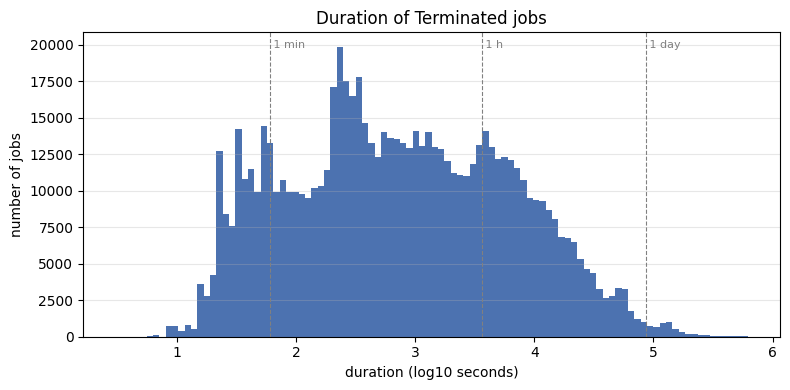

In [16]:
# Histogram of Terminated job durations on a log scale
import matplotlib.pyplot as plt
d = done.loc[done['duration'] > 0, 'duration']
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(d), bins=100, color='#4C72B0')
ax.set_xlabel('duration (log10 seconds)')
ax.set_ylabel('number of jobs')
ax.set_title('Duration of Terminated jobs')
ax.grid(axis='y', alpha=0.3)
for sec, label in [(60, '1 min'), (3600, '1 h'), (86400, '1 day')]:
    ax.axvline(np.log10(sec), color='gray', linestyle='--', linewidth=0.8)
    ax.text(np.log10(sec), ax.get_ylim()[1] * 0.95, f' {label}', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

In [17]:
# Requested resources per task: value distributions to infer units
for col in ['plan_cpu', 'plan_mem', 'plan_gpu']:
    s = task[col]
    print(f'=== {col} === missing share: {s.isna().mean():.3f}')
    print(s.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(2))
    print('most common values:', s.value_counts().head(8).to_dict(), '\n')

print('=== gpu_type (requested) ===')
print(task['gpu_type'].value_counts(dropna=False).head(10))

=== plan_cpu === missing share: 0.015
count    1242596.00
mean         633.37
std          591.51
min            0.00
5%           100.00
25%          600.00
50%          600.00
75%          600.00
95%         1800.00
99%         2000.00
max         9000.00
Name: plan_cpu, dtype: float64
most common values: {600.0: 782067, 100.0: 150400, 1800.0: 65572, 200.0: 43157, 800.0: 33299, 1000.0: 31700, 20.0: 31115, 400.0: 26715} 

=== plan_mem === missing share: 0.015
count    1242596.00
mean          28.36
std           19.55
min            0.00
5%             2.00
25%           29.30
50%           29.30
75%           29.30
95%           58.59
99%           78.12
max          400.00
Name: plan_mem, dtype: float64
most common values: {29.296875: 859923, 58.59375: 70494, 2.0: 49900, 19.53125: 40585, 9.765625: 32314, 19.55078125: 26869, 2.9296875: 16715, 39.0625: 12460} 

=== plan_gpu === missing share: 0.178
count    1037085.00
mean          68.26
std           74.26
min            1.00
5%     

In [18]:
# Machine capacities, to compare with the requests above
spec = load_table('machine_spec', INTERIM)
print('machines:', len(spec))
print(spec.value_counts(['gpu_type', 'cap_cpu', 'cap_mem', 'cap_gpu']).sort_index())

machines: 1897
gpu_type  cap_cpu  cap_mem  cap_gpu
CPU       96.0     512.0    0.0         83
MISC      96.0     512.0    8.0        280
P100      64.0     512.0    2.0        798
T4        96.0     512.0    2.0        497
V100      96.0     384.0    8.0         45
                   512.0    8.0         59
V100M32   96.0     384.0    8.0        135
Name: count, dtype: int64


In [19]:
# Do missing GPU requests coincide with gpu_type None?
print(pd.crosstab(task['plan_gpu'].isna().rename('plan_gpu missing'),
                  task['gpu_type'].fillna('None'), margins=True))

gpu_type            MISC    None   P100      T4   V100  V100M32      All
plan_gpu missing                                                        
False             693598       1  71344  225991  28144    18007  1037085
True                2683  217737   1388     932    653      572   223965
All               696281  217738  72732  226923  28797    18579  1261050


In [20]:
# Do requests fit the largest machine of the requested GPU type?
cap = spec.groupby('gpu_type')[['cap_cpu', 'cap_mem', 'cap_gpu']].max()
t = task.join(cap, on='gpu_type')
t = t[t['cap_gpu'].notna()]
print('tasks with a known machine type:', len(t))
print('plan_gpu > capacity:', (t['plan_gpu'] > 100 * t['cap_gpu']).sum())
print('plan_cpu > capacity:', (t['plan_cpu'] > 100 * t['cap_cpu']).sum())
print('plan_mem > capacity:', (t['plan_mem'] > t['cap_mem']).sum())
print('\nzero requests -> cpu:', (task['plan_cpu'] == 0).sum(),
      '| mem:', (task['plan_mem'] == 0).sum())
del t

tasks with a known machine type: 1043312
plan_gpu > capacity: 169
plan_cpu > capacity: 0
plan_mem > capacity: 0

zero requests -> cpu: 11 | mem: 0


## Sensor coverage and requested vs. actual usage

In [21]:
# Load the sensor table and check whether it has one row per instance attempt
sensor = load_table('sensor', INTERIM)
print('rows:', len(sensor), f'| memory: {sensor.memory_usage(deep=True).sum() / 1e9:.2f} GB')
print('duplicate worker_name:', sensor['worker_name'].duplicated().sum())
print('sensor rows whose worker is unknown in instance:',
      (~sensor['worker_name'].isin(inst['worker_name'])).sum())

rows: 3033232 | memory: 1.70 GB
duplicate worker_name: 0
sensor rows whose worker is unknown in instance: 13883


In [22]:
# Coverage: which attempts and which jobs have usage data?
has_sensor = inst['worker_name'].isin(sensor['worker_name'])
print('share of instance attempts with sensor data:', round(has_sensor.mean(), 4))
print('\nby attempt status:')
print(has_sensor.groupby(inst['status']).mean().round(3))

job_has_sensor = job['job_name'].isin(sensor['job_name'])
print('\nshare of jobs with any sensor data:', round(job_has_sensor.mean(), 4))
print('\nby job status:')
print(job_has_sensor.groupby(job['status']).mean().round(3))

share of instance attempts with sensor data: 0.4025

by attempt status:
status
Failed         0.446
Interrupted    0.465
Ready          0.000
Running        0.332
Terminated     0.425
Waiting        0.000
Name: worker_name, dtype: float64

share of jobs with any sensor data: 0.7935

by job status:
status
Failed        0.878
Running       0.577
Terminated    0.786
Waiting       0.007
Name: job_name, dtype: float64


In [23]:
# Within covered Terminated jobs: what share of their attempts has sensor data?
term_jobs = job.loc[job['status'] == 'Terminated', 'job_name']
cov = has_sensor.groupby(inst['job_name']).mean()
cov = cov[cov.index.isin(term_jobs) & (cov > 0)]
print('Terminated jobs with sensor data:', len(cov))
print('share of their attempts covered:')
print(cov.describe(percentiles=[.1, .25, .5, .75]).round(3))

Terminated jobs with sensor data: 575912
share of their attempts covered:
count    575912.000
mean          0.871
std           0.239
min           0.004
10%           0.480
25%           0.842
50%           1.000
75%           1.000
max           1.000
Name: worker_name, dtype: float64


In [24]:
# Usage columns: ranges and missing shares
usage_cols = ['cpu_usage', 'gpu_wrk_util', 'avg_mem', 'max_mem',
              'avg_gpu_wrk_mem', 'max_gpu_wrk_mem']
print(sensor[usage_cols].describe(percentiles=[.05, .5, .95, .99]).T.round(2))
print('\nmissing share:')
print(sensor[usage_cols].isna().mean().round(3))

                     count    mean     std  min    5%     50%     95%  \
cpu_usage        3027403.0  258.84  568.06  0.0  8.41  103.49  842.89   
gpu_wrk_util     3033232.0   10.45   30.00  0.0  0.00    1.47   50.25   
avg_mem          3032015.0    5.54   10.62  0.0  0.20    2.52   19.51   
max_mem          3033232.0   10.69   57.71  0.0  0.33    3.82   29.52   
avg_gpu_wrk_mem  3033232.0    1.72    6.11  0.0  0.00    0.41    7.37   
max_gpu_wrk_mem  3033232.0    2.34    7.72  0.0  0.00    0.65    8.37   

                     99%      max  
cpu_usage        3192.91  9206.33  
gpu_wrk_util       88.57   792.00  
avg_mem            42.12   391.63  
max_mem            79.70  2757.59  
avg_gpu_wrk_mem    12.13   253.23  
max_gpu_wrk_mem    14.86   253.65  

missing share:
cpu_usage          0.002
gpu_wrk_util       0.000
avg_mem            0.000
max_mem            0.000
avg_gpu_wrk_mem    0.000
max_gpu_wrk_mem    0.000
dtype: float64


In [25]:
# Requested vs actual usage per attempt (requests are defined per instance)
su = sensor[['job_name', 'task_name'] + usage_cols].merge(
    task[['job_name', 'task_name', 'plan_cpu', 'plan_mem', 'plan_gpu']],
    on=['job_name', 'task_name'], how='left')
ratios = pd.DataFrame({
    'cpu: used / requested': su['cpu_usage'] / su['plan_cpu'],
    'mem: max used / requested': su['max_mem'] / su['plan_mem'],
    'gpu: util / requested': su['gpu_wrk_util'] / su['plan_gpu'],
}).replace([np.inf, -np.inf], np.nan)
print(ratios.describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2))
print('\nshare of attempts using more than requested:')
print((ratios.gt(1).sum() / ratios.notna().sum()).round(3))

                               count  mean   std  min    5%   25%   50%   75%  \
cpu: used / requested      3016922.0  0.96  7.71  0.0  0.02  0.10  0.23  0.63   
mem: max used / requested  3022746.0  0.46  0.87  0.0  0.01  0.06  0.20  0.61   
gpu: util / requested      3022746.0  0.18  0.36  0.0  0.00  0.00  0.04  0.23   

                            95%     max  
cpu: used / requested      2.22  391.79  
mem: max used / requested  1.59   80.00  
gpu: util / requested      0.80   70.00  

share of attempts using more than requested:
cpu: used / requested        0.154
mem: max used / requested    0.120
gpu: util / requested        0.021
dtype: float64


## Time axis, arrivals and queueing

In [26]:
# Free memory from the sensor analysis, then check the time range
del su, ratios, sensor, has_sensor, cov
gc.collect()
t0, t1 = job['start_time'].min(), job['start_time'].max()
print(f'job start_time range: {t0:.0f} .. {t1:.0f} s -> {(t1 - t0) / 86400:.1f} days')
print(f'first job at day {t0 / 86400:.2f} of the relative clock')

job start_time range: 494319 .. 6451081 s -> 68.9 days
first job at day 5.72 of the relative clock


In [27]:
# Is job start_time the submission time? Compare it with the first instance start
first_start = inst.groupby('job_name')['start_time'].min()
gap = pd.Series(first_start.reindex(done['job_name']).values
                - done['start_time'].values).dropna()
print('Terminated jobs with a known instance start:', len(gap))
print('first instance start - job start_time (s):')
print(gap.describe(percentiles=[.01, .25, .5, .75, .9, .99]).round(1))
print('negative share:', round((gap < 0).mean(), 4), '| zero share:', round((gap == 0).mean(), 4))

Terminated jobs with a known instance start: 732355
first instance start - job start_time (s):
count    732355.0
mean        320.8
std        3820.0
min      -15479.0
1%            2.0
25%           3.0
50%           7.0
75%          13.0
90%         109.0
99%        5622.5
max      554254.0
dtype: float64
negative share: 0.0 | zero share: 0.0


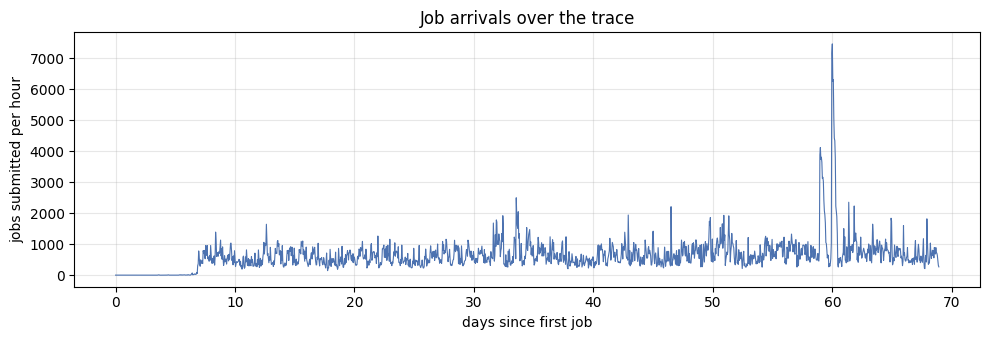

In [30]:
# Hourly job arrivals over the whole trace
hours = ((job['start_time'].dropna() - t0) // 3600).astype(int)
per_hour = hours.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(per_hour.index / 24, per_hour.values, linewidth=0.8, color='#4C72B0')
ax.set_xlabel('days since first job')
ax.set_ylabel('jobs submitted per hour')
ax.set_title('Job arrivals over the trace')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Who submitted the burst around day 59-60?
day = (job['start_time'] - t0) / 86400
burst = job[(day >= 58.8) & (day < 60.5)]
print('jobs in burst window:', len(burst))
print('\ntop users in burst (share):')
print(burst['user'].value_counts(normalize=True).head(5).round(3))
print('\nstatus in burst:')
print(burst['status'].value_counts(normalize=True).round(3))
print('\nstatus overall:')
print(job['status'].value_counts(normalize=True).round(3))

jobs in burst window: 99195

top users in burst (share):
user
58540f191766    0.825
5b1345f03aa1    0.015
d4d51aca8806    0.013
0ed3eacdff35    0.012
de69ddc1064e    0.010
Name: proportion, dtype: float64

status in burst:
status
Failed        0.795
Terminated    0.201
Running       0.005
Name: proportion, dtype: float64

status overall:
status
Terminated    0.694
Failed        0.243
Running       0.060
Waiting       0.003
Name: proportion, dtype: float64


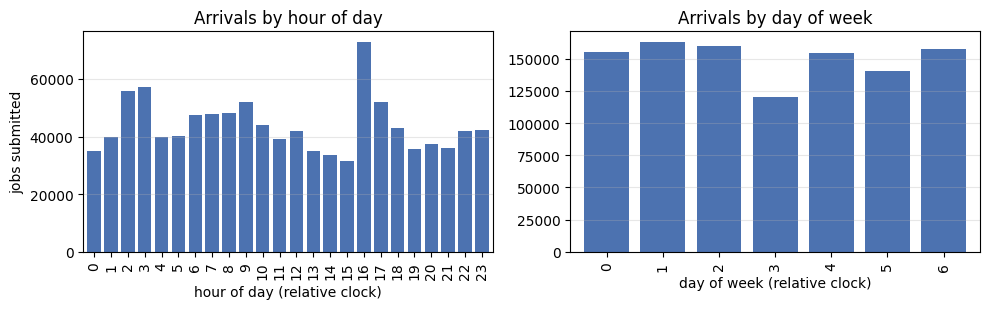

In [32]:
# Daily and weekly cycles after the sparse first week
# (relative clock: hour 0 is not necessarily midnight)
st = job['start_time'].dropna()
st = st[st >= t0 + 7 * 86400]
abs_hour = (st // 3600).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
(abs_hour % 24).value_counts().sort_index().plot.bar(ax=axes[0], color='#4C72B0', width=0.8)
axes[0].set_xlabel('hour of day (relative clock)')
axes[0].set_ylabel('jobs submitted')
axes[0].set_title('Arrivals by hour of day')
(abs_hour // 24 % 7).value_counts().sort_index().plot.bar(ax=axes[1], color='#4C72B0', width=0.8)
axes[1].set_xlabel('day of week (relative clock)')
axes[1].set_title('Arrivals by day of week')
for a in axes:
    a.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# group_tag: coverage and cardinality (joined to jobs via inst_id)
gt = load_table('group_tag', INTERIM)
print('rows:', len(gt), '| duplicate inst_id:', gt['inst_id'].duplicated().sum())
print('jobs with a group_tag row:', round(job['inst_id'].isin(gt['inst_id']).mean(), 4))
for col in ['user', 'gpu_type_spec', 'group', 'workload']:
    print(f'{col:14s} unique: {gt[col].nunique():>7}  missing share: {gt[col].isna().mean():.3f}')
print('\nmost common workloads:')
print(gt['workload'].value_counts().head(10))

rows: 1055032 | duplicate inst_id: 0
jobs with a group_tag row: 0.9986
user           unique:    1431  missing share: 0.000
gpu_type_spec  unique:       5  missing share: 0.980
group          unique:  316956  missing share: 0.000
workload       unique:       9  missing share: 0.903

most common workloads:
workload
bert          54887
ctr           27083
nmt           10363
inception      5440
graphlearn     3754
resnet          541
xlnet           415
rl              249
vgg              66
Name: count, dtype: int64


In [34]:
# How much of log-duration variance do simple categories explain? (in-sample, optimistic)
d = done[['job_name', 'inst_id', 'user', 'duration']].merge(
    gt[['inst_id', 'group', 'workload', 'gpu_type_spec']], on='inst_id', how='left')
first_task = task.drop_duplicates('job_name').set_index('job_name')['task_name']
d['task_name'] = d['job_name'].map(first_task)
d['log_dur'] = np.log10(d['duration'])
total_var = d['log_dur'].var()
for col in ['user', 'group', 'workload', 'gpu_type_spec', 'task_name']:
    grp_mean = d.groupby(col)['log_dur'].transform('mean')
    r2 = 1 - ((d['log_dur'] - grp_mean) ** 2).mean() / total_var
    single = (d[col].map(d[col].value_counts()) == 1).mean()
    print(f'{col:14s} groups: {d[col].nunique():>7}  explained var: {r2:.3f}  '
          f'singleton share: {single:.3f}  missing: {d[col].isna().mean():.3f}')

user           groups:    1307  explained var: 0.343  singleton share: 0.000  missing: 0.000
group          groups:  217981  explained var: 0.880  singleton share: 0.253  missing: 0.001
workload       groups:       9  explained var: 0.308  singleton share: 0.000  missing: 0.880
gpu_type_spec  groups:       4  explained var: 0.396  singleton share: 0.000  missing: 0.988
task_name      groups:      17  explained var: 0.041  singleton share: 0.000  missing: 0.000
